#  [TPU Train]

# Import libs 

In [1]:
# Install libs
!pip install -qq torch~=2.4.0 --index-url https://download.pytorch.org/whl/cpu --upgrade
!pip install -qq torch_xla[tpu]~=2.4.0 -f https://storage.googleapis.com/libtpu-releases/index.html --upgrade
!pip install -qq transformers==4.43.3 --upgrade
!pip install -qq peft==0.11.1 --upgrade
!pip install -qq pandas scikit-learn matplotlib
!pip uninstall -qq tensorflow -y

# !pip install git+https://github.com/huggingface/transformers.git

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchvision 0.18.0 requires torch==2.3.0, but you have torch 2.4.0+cpu which is incompatible.
torchaudio 2.3.0 requires torch==2.3.0, but you have torch 2.4.0+cpu which is incompatible.


In [2]:
import os
import gc
import re
from time import time, sleep
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import pickle
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, StratifiedKFold

import torch
import torch.nn as nn
import transformers
from transformers import GemmaTokenizerFast, Gemma2ForSequenceClassification, Gemma2Config
from transformers import AutoModelForSequenceClassification, AutoTokenizer, MistralConfig
from peft import get_peft_config, PeftModel, PeftConfig, get_peft_model, LoraConfig, TaskType, prepare_model_for_kbit_training
import torch.nn.functional as F

import torch_xla
import torch_xla.debug.profiler as xp
import torch_xla.core.xla_model as xm
import torch_xla.distributed.spmd as xs
import torch_xla.runtime as xr
import torch_xla.utils.serialization as xser
from torch_xla.distributed.spmd import XLAShardedTensor
from torch_xla.distributed.spmd import Mesh
xr.use_spmd(auto=True)
xr.initialize_cache('cache_xla', readonly=False)

tqdm.pandas()
DEVICE = xm.xla_device()

print(xm.get_xla_supported_devices(devkind="TPU"), xr.global_runtime_device_count())
print(f'Torch Version: {torch.__version__}')
print(f'Torch XLA Version: {torch_xla.__version__}')
print(f'Transformer Version: {transformers.__version__}')
# HF_TOKEN removed: the Gemma 2 weights load from /kaggle/input, so no Hub token is needed.

/usr/local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/usr/local/lib/python3.10/site-packages/torch_xla/core/xla_model.py:105: UserWarning: `devkind` argument is deprecated and will be removed in a future release.
  warnings.warn("`devkind` argument is deprecated and will be removed in a "


E0000 00:00:1722784344.181412      77 common_lib.cc:818] Could not set metric server port: INVALID_ARGUMENT: Could not find SliceBuilder port 8471 in any of the 0 ports provided in `tpu_process_addresses`="local"
=== Source Location Trace: ===
learning/45eac/tfrc/runtime/common_lib.cc:483
Traceback (most recent call last):
  File "/usr/local/lib/python3.10/site-packages/torch/_inductor/compile_worker/__main__.py", line 45, in <module>
    main()
  File "/usr/local/lib/python3.10/site-packages/torch/_inductor/compile_worker/__main__.py", line 38, in main
    pre_fork_setup()
  File "/usr/local/lib/python3.10/site-packages/torch/_inductor/async_compile.py", line 62, in pre_fork_setup
    from triton.compiler.compiler import triton_key
ImportError: cannot import name 'triton_key' from 'triton.compiler.compiler' (/usr/local/lib/python3.10/site-packages/triton/compiler/compiler.py)
W0804 15:12:28.403000 137095378917056 torch/_inductor/compile_worker/subproc_pool.py:126] SubprocPool unclean 

['xla:0'] 8
Torch Version: 2.4.0+cpu
Torch XLA Version: 2.4.0
Transformer Version: 4.43.3


# Configs

In [3]:
class CFG:
    NUM_EPOCHS = 1
    BATCH_SIZE = 8
    DROPOUT = 0.0
    MODEL_NAME = "/kaggle/input/gemma-2/transformers/gemma-2-9b-it/1" # google/gemma-2-9b-it
    SEED = 123
    MAX_LENGTH = 1536
    NUM_WARMUP_STEPS_FRAC = 0.1
    LR_MAX = 2e-4
    NUM_LABELS = 3
    LORA_RANK = 16
    LORA_ALPHA = LORA_RANK
    LORA_MODULES = ['q_proj', 'k_proj', 'v_proj', 'o_proj', "gate_proj", "up_proj", "down_proj",]
    LORA_INIT = "pissa_niter_16"
    LORA_DORA = True
    AMSGRAD = False
    WEIGHTS_PATH = "/kaggle/input/train-v4-15/transformers/default/1/gemma2_model_current.pth"

In [4]:
def set_seeds(seed):
    """Set seeds for reproducibility """
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        
    # Set seed for all TPU cores
    xm.set_rng_state(seed, device=xm.xla_device())

set_seeds(seed=CFG.SEED)


GEMMA_RULES = (
    ("model\\.embed_tokens", ("mp", ("fsdp", "sp"))),
    ("self_attn\\.(q_proj|k_proj|v_proj)", (("fsdp", "sp"), "mp")),
    ("self_attn\\.o_proj", ("mp", ("fsdp", "sp"))),
    ("mlp\\.gate_proj", (("fsdp", "sp"), "mp")),
    ("mlp\\.down_proj", ("mp", ("fsdp", "sp"))),
    ("mlp\\.up_proj", (("fsdp", "sp"), "mp")),
    ("lm_head", (("fsdp", "sp"), "mp")),
    ("score", (("fsdp", "sp"), "mp")),
    )

ALL_RULES = [
    (Gemma2Config, GEMMA_RULES),
    (MistralConfig, GEMMA_RULES),
]

def find_rule(model):
    for config, rule in ALL_RULES:
        if model.config.__class__ == config:
            return rule
    raise Exception("unsupported model to partitioning " + str(model.config.__class__))


def partition_module2(model, mesh, device='xla', verbose=False):
    
    strkey2id = {
        "dp": 0,
        "fsdp": 1,
        "mp": 2,
        "sp": 3,
    }

    partition_specs = find_rule(model)
    model.to(device)

    for name, module in (tqdm(model.named_modules(), desc="partitioning model", disable=not verbose, position=0)):
        if not hasattr(module, "weight") or not isinstance(module.weight, nn.Parameter):
            continue
        find = False
        for rule_pattern, spec in partition_specs:
            if re.findall(rule_pattern, name):
                if verbose:
                    print("match", rule_pattern, name, spec)
                
                xs.mark_sharding(module.weight, mesh, spec)
                find = True
                break
        if not find:
            if verbose:
                print(f"no match {module}", name, module.weight.size(), module.weight.dim())
            xs.mark_sharding(module.weight, mesh, tuple([None] * module.weight.dim()))

In [5]:
def get_token_lengths(texts):
    input_ids = tokenizer(texts.tolist(), return_tensors='np')['input_ids']
    return [len(t) for t in input_ids]


def process_bad_string(string_):
    return string_.encode('utf-8', 'ignore').decode()
    

def process_prompt_respond_AB(list_prompt, list_responseA, list_responseB, init_res=1, max_res=2):
    len_res = len(list_prompt)
    processed_string = ""
    for i in range(min(init_res, len_res)):
        processed_string = (processed_string 
                            + "QUERY: " + process_bad_string(str(list_prompt[i])) 
                            + "\n\nANSWER 1: " + process_bad_string(str(list_responseA[i])) 
                            + "\n\nANSWER 2: " + process_bad_string(str(list_responseB[i])) 
                            + "\n\n")

    start_idx = min(max(init_res - max_res, init_res - len_res), 0)
    for j in range(start_idx, 0, 1):
        processed_string = (processed_string 
                            + "QUERY: " + process_bad_string(str(list_prompt[j])) 
                            + "\n\nANSWER 1: " + process_bad_string(str(list_responseA[j])) 
                            + "\n\nANSWER 2: " + process_bad_string(str(list_responseB[j])) 
                            + "\n\n")
        
    processed_string = processed_string + "The better answer is:"
    
    return processed_string

# Tokenizer

In [6]:
if os.environ.get('KAGGLE_URL_BASE',''):
    cache_dir = None
else:
    cache_dir = 'cache'

tokenizer = AutoTokenizer.from_pretrained(CFG.MODEL_NAME)
tokenizer.padding_side = 'right'
tokenizer.add_eos_token = True
tokenizer.truncation_side = 'left'

model = AutoModelForSequenceClassification.from_pretrained(
                CFG.MODEL_NAME,
                num_labels=CFG.NUM_LABELS,
                torch_dtype=torch.bfloat16,
                cache_dir=cache_dir,
#                 local_files_only=True,
            )
model.config.use_cache = False

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
    model.config.pad_token_id = model.config.eos_token_id

print(model)

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Loading checkpoint shards:  25%|██▌       | 1/4 [00:00<00:01,  2.15it/s]

Loading checkpoint shards:  50%|█████     | 2/4 [00:01<00:01,  1.95it/s]

Loading checkpoint shards:  75%|███████▌  | 3/4 [00:01<00:00,  1.91it/s]

Loading checkpoint shards: 100%|██████████| 4/4 [00:02<00:00,  1.95it/s]

Loading checkpoint shards: 100%|██████████| 4/4 [00:02<00:00,  1.96it/s]


Some weights of Gemma2ForSequenceClassification were not initialized from the model checkpoint at /kaggle/input/gemma-2/transformers/gemma-2-9b-it/1 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Gemma2ForSequenceClassification(
  (model): Gemma2Model(
    (embed_tokens): Embedding(256000, 3584, padding_idx=0)
    (layers): ModuleList(
      (0-41): 42 x Gemma2DecoderLayer(
        (self_attn): Gemma2Attention(
          (q_proj): Linear(in_features=3584, out_features=4096, bias=False)
          (k_proj): Linear(in_features=3584, out_features=2048, bias=False)
          (v_proj): Linear(in_features=3584, out_features=2048, bias=False)
          (o_proj): Linear(in_features=4096, out_features=3584, bias=False)
          (rotary_emb): Gemma2RotaryEmbedding()
        )
        (mlp): Gemma2MLP(
          (gate_proj): Linear(in_features=3584, out_features=14336, bias=False)
          (up_proj): Linear(in_features=3584, out_features=14336, bias=False)
          (down_proj): Linear(in_features=14336, out_features=3584, bias=False)
          (act_fn): PytorchGELUTanh()
        )
        (input_layernorm): Gemma2RMSNorm()
        (post_attention_layernorm): Gemma2RMSNorm()
        (pre

In [7]:
def generate_mid_idx(n_dup, n_total=42, align='mid'):
    start_idx = (n_total//2) - (n_dup//2)
    end_idx = start_idx + n_dup
    layer_replication = [[0, end_idx], [start_idx, n_total]]
    if align == 'mid':
        layers_to_transform = list(range(start_idx + (n_dup//2), end_idx + (n_dup//2)))
    elif align == 'left':
        layers_to_transform = list(range(start_idx, end_idx))
    elif align == 'right':
        layers_to_transform = list(range(start_idx + n_dup, end_idx + n_dup))
    return layer_replication, layers_to_transform

In [8]:
layer_replication, layers_to_transform = generate_mid_idx(n_dup=10, n_total=42, align='left')

lora_config = LoraConfig(
    r=CFG.LORA_RANK,
    lora_alpha = CFG.LORA_ALPHA,
    lora_dropout= CFG.DROPOUT, 
    # bias='lora_only',
    task_type=TaskType.SEQ_CLS,
    target_modules=CFG.LORA_MODULES,
    init_lora_weights=CFG.LORA_INIT,
    use_dora=CFG.LORA_DORA,
    layer_replication=layer_replication,
    layers_to_transform=layers_to_transform,
)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()
print(model)

trainable params: 13,312,512 || all params: 9,255,029,248 || trainable%: 0.1438
PeftModelForSequenceClassification(
  (base_model): LoraModel(
    (model): Gemma2ForSequenceClassification(
      (model): Gemma2Model(
        (embed_tokens): Embedding(256000, 3584, padding_idx=0)
        (layers): ModuleList(
          (0-15): 16 x Gemma2DecoderLayer(
            (self_attn): Gemma2Attention(
              (q_proj): Linear(in_features=3584, out_features=4096, bias=False)
              (k_proj): Linear(in_features=3584, out_features=2048, bias=False)
              (v_proj): Linear(in_features=3584, out_features=2048, bias=False)
              (o_proj): Linear(in_features=4096, out_features=3584, bias=False)
              (rotary_emb): Gemma2RotaryEmbedding()
            )
            (mlp): Gemma2MLP(
              (gate_proj): Linear(in_features=3584, out_features=14336, bias=False)
              (up_proj): Linear(in_features=3584, out_features=14336, bias=False)
              (down_pro

In [9]:
# Number of TPU Nodes
num_devices = xr.global_runtime_device_count()
mesh_shape = (1, num_devices, 1, 1)
device_ids = np.array(range(num_devices))
mesh = Mesh(device_ids, mesh_shape, ('dp', 'fsdp', 'mp', 'sp'))
partition_module2(model, mesh)
print(f'num_devices: {num_devices}')

num_devices: 8


# Prepare train


In [10]:
def generate_swap_samples(df):
    df_ = df.copy()
    df_ = df.rename(columns={'response_a':'response_b', 'response_b':'response_a', 
                             'winner_model_a':'winner_model_b', 'winner_model_b':'winner_model_a'})
    df_['id'] = 'Rep_' + df_['id'].astype(str)
    df_["text"] = df_.apply(lambda x: process_prompt_respond_AB(list_prompt=x['prompt'], 
                                                                list_responseA=x['response_a'],
                                                                list_responseB=x['response_b'],
                                                                init_res=0, max_res=5
                                                               ), axis=1)
    df_ = pd.concat([df, df_[df.columns]], axis=0, ignore_index=True)
    return df_


def remove_extra_tokens(df):
    df_ = df.copy()
    for n_res in range(4, 0, -1):
        mask = (df_['token_count'] >= CFG.MAX_LENGTH)
        df_.loc[mask, "text"] = df_.loc[mask, :].apply(lambda x: process_prompt_respond_AB(list_prompt=x['prompt'], 
                                                            list_responseA=x['response_a'],
                                                            list_responseB=x['response_b'],
                                                            init_res=0, max_res=n_res), axis=1)
        df_.loc[:, 'token_count'] = get_token_lengths(df_['text'])
    return df_

In [11]:
labels = ['winner_model_a', 'winner_model_b', 'winner_tie']

if os.environ.get('KAGGLE_URL_BASE',''):
    train = pd.read_csv("/kaggle/input/lmsys-chatbot-arena/train.csv")
else:
    train = pd.read_csv("./input/train.csv")

train['pair'] = train['model_a'] + ' - ' + train['model_b']
train = train.groupby('pair').sample(frac=0.5, random_state=CFG.SEED).drop(columns='pair')
train = train.drop_duplicates(keep="first", ignore_index=True)

train['id'] = train['id'].astype(str)
for col in ["prompt", "response_a", "response_b"]:
    train[col] = train[col].apply(lambda x: eval(x.replace(r"\/", "/").replace("null", "None")))

train["text"] = train.apply(lambda x: process_prompt_respond_AB(list_prompt=x['prompt'], 
                                                                list_responseA=x['response_a'],
                                                                list_responseB=x['response_b'],
                                                                init_res=0, max_res=5
                                                               ), axis=1)

train.loc[:, 'token_count'] = get_token_lengths(train['text'])
train.loc[:, 'label'] = np.argmax(train[['winner_model_a','winner_model_b','winner_tie']].values, axis=1)

train, valid = train_test_split(train, test_size=0.5, random_state=CFG.SEED)

# train = generate_swap_samples(train)

train = remove_extra_tokens(train)
valid = remove_extra_tokens(valid)

train = train.sample(frac=1.0, random_state=CFG.SEED).reset_index(drop=True)
display(train.shape)

(14331, 12)

In [12]:
# Tokenize Data
tokens = tokenizer(
    train['text'].tolist(),
    padding='max_length',
    max_length=CFG.MAX_LENGTH,
    truncation=True,
    return_tensors='np')

# Input IDs are the token IDs
INPUT_IDS = tokens['input_ids']
# Attention Masks to Ignore Padding Tokens
ATTENTION_MASKS = tokens['attention_mask']
# Label of Texts
LABELS = train[['winner_model_a','winner_model_b','winner_tie']].values

print(f'INPUT_IDS shape: {INPUT_IDS.shape}, ATTENTION_MASKS shape: {ATTENTION_MASKS.shape}')
print(f'LABELS shape: {LABELS.shape}')

def create_dataset(batch_size, INPUT_IDS_, ATTENTION_MASKS_, LABELS_, DEVICE_, mesh_, id_list_, seed_=None):
    N_SAMPLES = LABELS_.shape[0]
    IDXS = np.arange(N_SAMPLES - (N_SAMPLES % batch_size))
    rng = np.random.RandomState(seed_)
    while True:
        if seed_ is not None:
            print("DATA SEED:", seed_)
            rng.shuffle(IDXS)
        for idxs in IDXS.reshape(-1, batch_size):
            
            id_list = id_list_[idxs]
            
            input_ids = torch.tensor(INPUT_IDS_[idxs]).to(DEVICE_)
            attention_mask = torch.tensor(ATTENTION_MASKS_[idxs]).to(DEVICE_)
            labels = torch.tensor(LABELS_[idxs]).to(DEVICE_)

            xs.mark_sharding(input_ids, mesh_, (0, 1))
            xs.mark_sharding(attention_mask, mesh_, (0, 1))
            xs.mark_sharding(labels, mesh_, (0, 1))
            
            yield input_ids, attention_mask, labels, id_list

INPUT_IDS shape: (14331, 1536), ATTENTION_MASKS shape: (14331, 1536)
LABELS shape: (14331, 3)


# Training

In [13]:
# LR & Optimizer
N_SAMPLES = len(train)
STEPS_PER_EPOCH = N_SAMPLES // CFG.BATCH_SIZE

OPTIMIZER = torch.optim.AdamW(model.parameters(), lr=CFG.LR_MAX, amsgrad=CFG.AMSGRAD, weight_decay=1e-2)

# Cosine Learning Rate With Warmup
lr_scheduler = transformers.get_cosine_schedule_with_warmup(
    optimizer=OPTIMIZER,
    num_warmup_steps=int(CFG.NUM_WARMUP_STEPS_FRAC * STEPS_PER_EPOCH * CFG.NUM_EPOCHS),
    num_training_steps=STEPS_PER_EPOCH * CFG.NUM_EPOCHS)

print(f'BATCH_SIZE: {CFG.BATCH_SIZE}, N_SAMPLES: {N_SAMPLES}, STEPS_PER_EPOCH: {STEPS_PER_EPOCH}')

# Set the data type for the optimizer's state (e.g., momentum buffers)
for state in OPTIMIZER.state.values():
    for k, v in state.items():
        if isinstance(v, torch.Tensor) and (state[k].dtype is not torch.float32):
            state[v] = v.to(dtype=torch.float32)

# Loss Function, Cross Entropy
LOSS_FN = torch.nn.CrossEntropyLoss().to(dtype=torch.float32)

BATCH_SIZE: 8, N_SAMPLES: 14331, STEPS_PER_EPOCH: 1791


In [14]:
model.train()
st = time()
warnings.filterwarnings("error")
METRICS = {
    'loss': [],
    'accuracy': {'y_true': [], 'y_pred': []},
    'id': [], 'logits': [],
}

for epoch in tqdm(range(CFG.NUM_EPOCHS)):
    ste = time()
    TRAIN_DATASET = create_dataset(CFG.BATCH_SIZE, INPUT_IDS, ATTENTION_MASKS, LABELS, 
                                   DEVICE, mesh, id_list_=train['id'].to_numpy(), seed_=(CFG.SEED+epoch))
    for step in range(STEPS_PER_EPOCH):
        OPTIMIZER.zero_grad()
        input_ids, attention_mask, labels, id_list = next(TRAIN_DATASET)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        logits = outputs.logits.to(dtype=torch.float32)
        loss = LOSS_FN(logits, labels.to(dtype=torch.float32))
        loss.backward()
        OPTIMIZER.step()
        xm.mark_step()
        
        # Update Learning Rate Scheduler
        lr_scheduler.step()
        
        # Update Metrics And Progress Bar
        METRICS['loss'].append(float(loss))
        METRICS['accuracy']['y_true'] = METRICS['accuracy']['y_true'] + labels.squeeze().tolist()
        METRICS['accuracy']['y_pred'] = METRICS['accuracy']['y_pred'] + torch.argmax(F.softmax(logits, dim=-1), dim=1).cpu().tolist()
        METRICS['logits'] = METRICS['logits'] + [logits.detach().cpu().numpy()]
        METRICS['id'] = METRICS['id'] + list(id_list)

        obs_check = int(N_SAMPLES*0.1)
        
        if (step % 10) == 0:
            metrics = 'µ_loss: {:.3f}'.format(np.mean(METRICS['loss'][-int(obs_check / CFG.BATCH_SIZE):]))
            metrics += ', step_loss: {:.3f}'.format(np.mean(METRICS['loss'][-10:]))
            metrics += ', µ_auc: {:.3f}'.format(accuracy_score(torch.argmax(torch.tensor(METRICS['accuracy']['y_true'][-obs_check:]), axis=-1), \
                                                               METRICS['accuracy']['y_pred'][-obs_check:]))
            lr = OPTIMIZER.param_groups[0]['lr']
            print(f'{epoch+1:02}/{CFG.NUM_EPOCHS:02} | {step:04}/{STEPS_PER_EPOCH} lr: {lr:.2E}, {metrics}', end='')
            print(f'\nSteps per epoch: {step} complete | Time elapsed: {time()- st}')
    
    print(f'\nEpoch {epoch+1} Completed | Total time for epoch: {time() - ste} ')

with open('train_metrics_current.pkl', 'wb') as fp:
    pickle.dump(METRICS, fp)

  0%|          | 0/1 [00:00<?, ?it/s]

DATA SEED: 123


01/01 | 0000/1791 lr: 1.12E-06, µ_loss: 1.697, step_loss: 1.697, µ_auc: 0.500
Steps per epoch: 0 complete | Time elapsed: 392.7544274330139


01/01 | 0010/1791 lr: 1.23E-05, µ_loss: 1.725, step_loss: 1.728, µ_auc: 0.352
Steps per epoch: 10 complete | Time elapsed: 1240.8695781230927


01/01 | 0020/1791 lr: 2.35E-05, µ_loss: 1.609, step_loss: 1.481, µ_auc: 0.333
Steps per epoch: 20 complete | Time elapsed: 1273.4826583862305


01/01 | 0030/1791 lr: 3.46E-05, µ_loss: 1.498, step_loss: 1.266, µ_auc: 0.355
Steps per epoch: 30 complete | Time elapsed: 1306.3192150592804


... (174 outputs left out)

01/01 | 1780/1791 lr: 1.90E-08, µ_loss: 0.942, step_loss: 0.917, µ_auc: 0.546
Steps per epoch: 1780 complete | Time elapsed: 7059.799656629562


100%|██████████| 1/1 [1:58:13<00:00, 7093.18s/it]

100%|██████████| 1/1 [1:58:13<00:00, 7093.18s/it]

01/01 | 1790/1791 lr: 0.00E+00, µ_loss: 0.946, step_loss: 0.907, µ_auc: 0.542
Steps per epoch: 1790 complete | Time elapsed: 7093.1849682331085

Epoch 1 Completed | Total time for epoch: 7093.1830422878265 


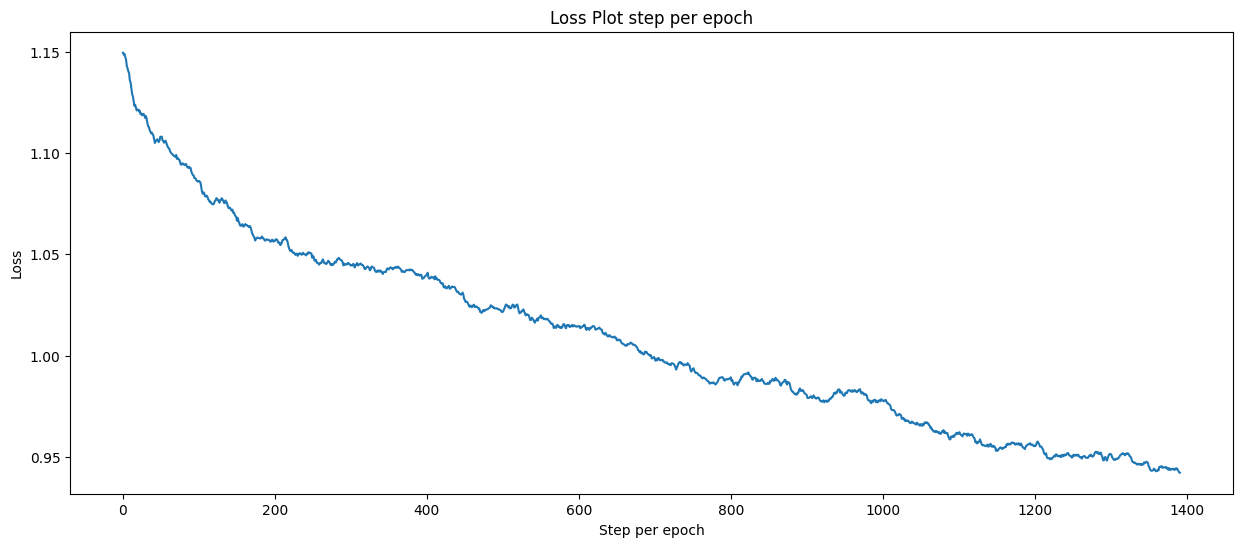

In [15]:
def moving_average(a, n=5):
    ret = np.cumsum(a, dtype=float)
    ret[n:] = ret[n:] - ret[:-n]
    return ret[n - 1:] / n

plt.figure(figsize=(15, 6))
plt.plot(moving_average(METRICS['loss'], n=400))
plt.xlabel('Step per epoch')
plt.ylabel('Loss')
plt.title('Loss Plot step per epoch')
plt.savefig('train_plot_current.png', bbox_inches='tight')
plt.show()

# Valid

In [16]:
# Tokenize Data
valid_sample = valid.sample(min(10000, len(valid)), random_state=CFG.SEED)

tokens_valid = tokenizer(
    valid_sample['text'].tolist(),
    padding='max_length',
    max_length=CFG.MAX_LENGTH,
    truncation=True,
    return_tensors='np')

LABELS_VALID = valid_sample[['winner_model_a','winner_model_b','winner_tie']].values
INPUT_IDS_VALID = tokens_valid['input_ids']
ATTENTION_MASKS_VALID = tokens_valid['attention_mask']

eval_size = 64

VALID_DATASET = create_dataset(eval_size, INPUT_IDS_VALID, ATTENTION_MASKS_VALID, LABELS_VALID, DEVICE, mesh,
                               id_list_=valid_sample['id'].to_numpy(), seed_=None)

model.eval()

LOSS_FN = torch.nn.CrossEntropyLoss().to(dtype=torch.float32)
METRICS_valid = {'loss': [], 'accuracy': {'y_true': [], 'y_pred': []}, 'id': [], 'logits': [],}
STEPS = len(valid_sample) // eval_size

for step in tqdm(range(STEPS)):
    with torch.no_grad():
        input_ids, attention_mask, labels, id_list = next(VALID_DATASET)
        
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        logits = outputs.logits.to(dtype=torch.float32)
        loss = LOSS_FN(logits, labels.to(dtype=torch.float32))
        
        METRICS_valid['loss'].append(float(loss))
        METRICS_valid['accuracy']['y_true'] = METRICS_valid['accuracy']['y_true'] + labels.squeeze().tolist()
        METRICS_valid['accuracy']['y_pred'] = METRICS_valid['accuracy']['y_pred'] + torch.argmax(F.softmax(logits, dim=-1), dim=1).cpu().tolist()
        METRICS_valid['id'] = METRICS_valid['id'] + list(id_list)
        METRICS_valid['logits'] = METRICS_valid['logits'] + [logits.detach().cpu().numpy()]
        
# Compute and display the validation results
print(f"Number of validation data {len(valid_sample)}\n")
print(f"Loss (valid): {np.mean(METRICS_valid['loss']):.3f}\n")
print(f"Accuracy (valid): {accuracy_score(torch.argmax(torch.tensor(METRICS_valid['accuracy']['y_true']), axis=-1), METRICS_valid['accuracy']['y_pred']):.2f}")
with open('valid_metrics_current.pkl', 'wb') as fp:
    pickle.dump(METRICS_valid, fp)

  0%|          | 0/156 [00:00<?, ?it/s]

  1%|          | 1/156 [11:23<29:26:41, 683.88s/it]

  1%|▏         | 2/156 [11:41<12:29:50, 292.14s/it]

  2%|▏         | 3/156 [11:59<7:05:37, 166.91s/it] 

  3%|▎         | 4/156 [12:17<4:33:50, 108.10s/it]

  3%|▎         | 5/156 [12:35<3:10:11, 75.57s/it] 

... (149 outputs left out)

 99%|█████████▉| 155/156 [57:25<00:17, 17.94s/it]

100%|██████████| 156/156 [57:43<00:00, 17.94s/it]

100%|██████████| 156/156 [57:43<00:00, 22.20s/it]

Number of validation data 10000

Loss (valid): 0.944

Accuracy (valid): 0.55


## Storage

In [17]:
obs_check = int(N_SAMPLES*0.1)
loss_check = METRICS['loss'][-int(obs_check / CFG.BATCH_SIZE):]
print(f"Mean: {np.mean(loss_check):.4f}, Mean std: {np.std(loss_check) / (len(loss_check)**0.5):.4f}")

# model_base_weight_dict = dict()
# for k, v in model.named_parameters():
#     if any([f".{x}." in k for x in layers_to_transform]) and ("base_layer.weight" in k):
#         print(k)
#         model_base_weight_dict[k] = v.cpu()
#     if k == 'base_model.model.score.original_module.weight':
#         print(k)
#         model_base_weight_dict[k] = v.cpu()
# xm.save(model_base_weight_dict, 'model_base_weight_dict_infer.pth')

# model = model.cpu()
# model.save_pretrained('./lora_adapter')

Mean: 0.9458, Mean std: 0.0132
